# Loan Default Risk: Data Inspection, EDA and Preliminary Experiments


Step 1. Initialize SparkSession

In [11]:
import os
import sys

os.environ["JAVA_HOME"] = "/opt/homebrew/opt/openjdk@17/libexec/openjdk.jdk/Contents/Home"
os.environ.pop("SPARK_HOME", None)
os.environ.pop("SPARK_CONF_DIR", None)
os.environ.pop("PYSPARK_SUBMIT_ARGS", None)
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

from pyspark.sql import SparkSession
from pyspark.sql.functions import (
    col, count, sum, avg, when, round,
    desc, corr, lit
)
from pyspark.sql.types import IntegerType, DoubleType, StringType

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

spark = (
    SparkSession.builder
    .appName("LoanDefaultRiskPrediction")
    .master("local[2]")
    .config("spark.sql.shuffle.partitions", "4")
    .config("spark.ui.enabled", "false")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")

print("Spark Version:", spark.version)
print("Spark initialized successfully!")

Spark Version: 3.5.6
Spark initialized successfully!


In [13]:
from pathlib import Path

# Resolve the project root whether the notebook is run from Notebooks/ or from the project root.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "Notebooks" else Path.cwd()
file_path = str(PROJECT_ROOT / "data" / "raw" / "Loan_default .csv")
GRAPHS_DIR = PROJECT_ROOT / "outputs" / "graphs"
GRAPHS_DIR.mkdir(parents=True, exist_ok=True)

df = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv(file_path)
)

print("Total Rows:", df.count())
print("Total Columns:", len(df.columns))

df.printSchema()
df.show(5, truncate=False)

Total Rows: 5000
Total Columns: 18
root
 |-- LoanID: string (nullable = true)
 |-- Age: integer (nullable = true)
 |-- Income: integer (nullable = true)
 |-- LoanAmount: integer (nullable = true)
 |-- CreditScore: integer (nullable = true)
 |-- MonthsEmployed: integer (nullable = true)
 |-- NumCreditLines: integer (nullable = true)
 |-- InterestRate: double (nullable = true)
 |-- LoanTerm: integer (nullable = true)
 |-- DTIRatio: double (nullable = true)
 |-- Education: string (nullable = true)
 |-- EmploymentType: string (nullable = true)
 |-- MaritalStatus: string (nullable = true)
 |-- HasMortgage: string (nullable = true)
 |-- HasDependents: string (nullable = true)
 |-- LoanPurpose: string (nullable = true)
 |-- HasCoSigner: string (nullable = true)
 |-- Default: integer (nullable = true)

+----------+---+------+----------+-----------+--------------+--------------+------------+--------+--------+-----------+--------------+-------------+-----------+-------------+-----------+--------

Step 3 — Check missing values and class distribution

In [14]:
# Missing values
missing_values = df.select([
    count(when(col(c).isNull(), 1)).alias(c)
    for c in df.columns
])

missing_values.show()

# Target distribution
df.groupBy("Default").count().orderBy("Default").show()

+------+---+------+----------+-----------+--------------+--------------+------------+--------+--------+---------+--------------+-------------+-----------+-------------+-----------+-----------+-------+
|LoanID|Age|Income|LoanAmount|CreditScore|MonthsEmployed|NumCreditLines|InterestRate|LoanTerm|DTIRatio|Education|EmploymentType|MaritalStatus|HasMortgage|HasDependents|LoanPurpose|HasCoSigner|Default|
+------+---+------+----------+-----------+--------------+--------------+------------+--------+--------+---------+--------------+-------------+-----------+-------------+-----------+-----------+-------+
|     0|  0|     0|         0|          0|             0|             0|           0|       0|       0|        0|             0|            0|          0|            0|          0|          0|      0|
+------+---+------+----------+-----------+--------------+--------------+------------+--------+--------+---------+--------------+-------------+-----------+-------------+-----------+-----------+----

Step 4 — Check duplicates and target distribution visually

In [17]:
print("Duplicate rows:",
      df.count() - df.dropDuplicates().count())

print("Unique Loan IDs:",
      df.select("LoanID").distinct().count())




Duplicate rows: 0
Unique Loan IDs: 5000


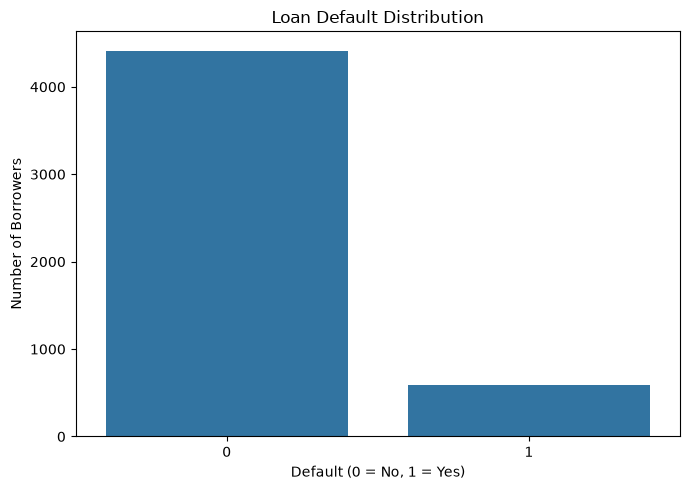

In [18]:
target_pd = df.groupBy("Default").count().toPandas()

plt.figure(figsize=(7, 5))

sns.barplot(
    data=target_pd,
    x="Default",
    y="count"
)

plt.title("Loan Default Distribution")
plt.xlabel("Default (0 = No, 1 = Yes)")
plt.ylabel("Number of Borrowers")

plt.tight_layout()

plt.savefig(
    GRAPHS_DIR / "default_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Step 4: Exploratory Data Analysis (EDA).

4.1 Default rate by categorical features

In [19]:
from pyspark.sql.functions import avg, round, count

categorical_cols = [
    "EmploymentType",
    "Education",
    "MaritalStatus",
    "LoanPurpose"
]

for feature in categorical_cols:
    print(f"\nDefault Rate by {feature}")

    result = (
        df.groupBy(feature)
        .agg(
            count("*").alias("Total_Loans"),
            round(avg("Default") * 100, 2).alias("Default_Rate")
        )
        .orderBy(desc("Default_Rate"))
    )

    result.show()


Default Rate by EmploymentType
+--------------+-----------+------------+
|EmploymentType|Total_Loans|Default_Rate|
+--------------+-----------+------------+
|    Unemployed|       1258|       13.59|
|     Part-time|       1234|       12.32|
| Self-employed|       1292|       10.91|
|     Full-time|       1216|       10.03|
+--------------+-----------+------------+


Default Rate by Education
+-----------+-----------+------------+
|  Education|Total_Loans|Default_Rate|
+-----------+-----------+------------+
| Bachelor's|       1275|       13.18|
|High School|       1264|        12.1|
|        PhD|       1244|       11.17|
|   Master's|       1217|       10.35|
+-----------+-----------+------------+


Default Rate by MaritalStatus
+-------------+-----------+------------+
|MaritalStatus|Total_Loans|Default_Rate|
+-------------+-----------+------------+
|     Divorced|       1647|        13.3|
|       Single|       1687|       11.14|
|      Married|       1666|       10.74|
+-------------

4.2 Visualize employment type and default rate

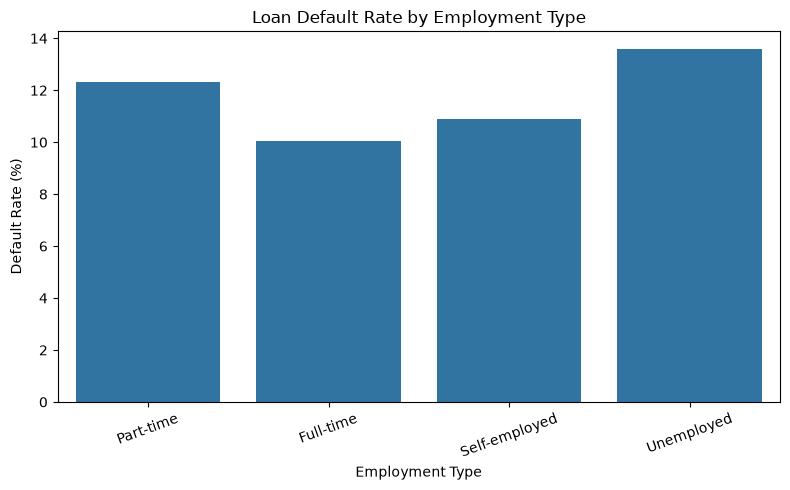

In [20]:
employment_pd = (
    df.groupBy("EmploymentType")
    .agg(
        round(avg("Default") * 100, 2).alias("Default_Rate")
    )
    .toPandas()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=employment_pd,
    x="EmploymentType",
    y="Default_Rate"
)

plt.title("Loan Default Rate by Employment Type")
plt.xlabel("Employment Type")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=20)

plt.tight_layout()

plt.savefig(
    GRAPHS_DIR / "default_by_employment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

4.3 Numerical feature analysis


In [21]:
numeric_features = [
    "Age",
    "Income",
    "LoanAmount",
    "CreditScore",
    "MonthsEmployed",
    "InterestRate",
    "DTIRatio"
]

numeric_analysis = (
    df.groupBy("Default")
    .agg(*[
        round(avg(c), 2).alias(c)
        for c in numeric_features
    ])
    .orderBy("Default")
)

numeric_analysis.show(truncate=False)

+-------+-----+--------+----------+-----------+--------------+------------+--------+
|Default|Age  |Income  |LoanAmount|CreditScore|MonthsEmployed|InterestRate|DTIRatio|
+-------+-----+--------+----------+-----------+--------------+------------+--------+
|0      |44.63|84001.37|126775.34 |578.75     |60.08         |13.12       |0.5     |
|1      |35.68|73063.62|142540.26 |552.23     |50.33         |15.94       |0.51    |
+-------+-----+--------+----------+-----------+--------------+------------+--------+



4.5 Visualize credit score and loan amount


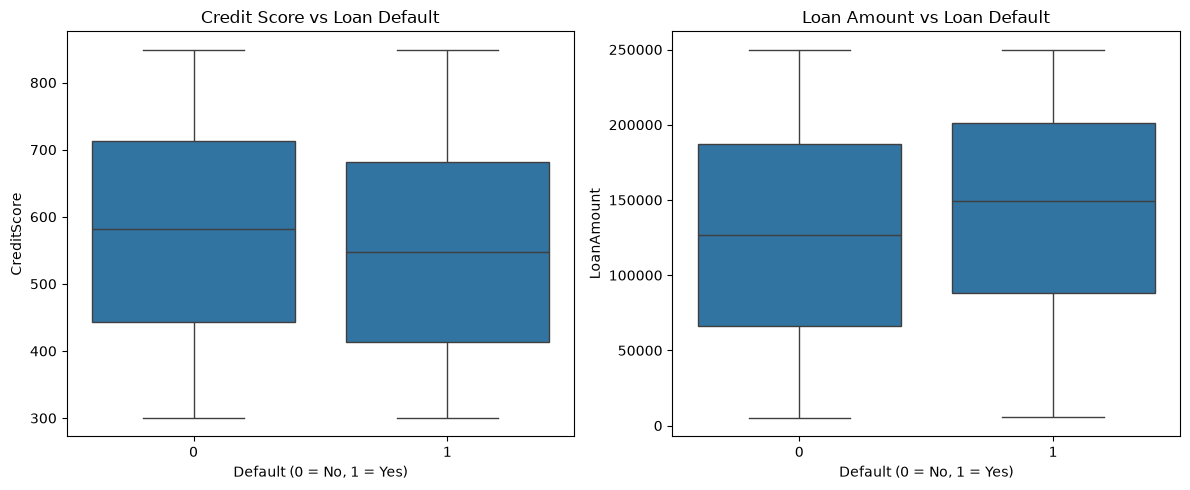

In [22]:
plot_df = df.select(
    "Default", "CreditScore", "LoanAmount"
).toPandas()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(
    data=plot_df,
    x="Default",
    y="CreditScore",
    ax=axes[0]
)
axes[0].set_title("Credit Score vs Loan Default")
axes[0].set_xlabel("Default (0 = No, 1 = Yes)")

sns.boxplot(
    data=plot_df,
    x="Default",
    y="LoanAmount",
    ax=axes[1]
)
axes[1].set_title("Loan Amount vs Loan Default")
axes[1].set_xlabel("Default (0 = No, 1 = Yes)")

plt.tight_layout()

plt.savefig(
    GRAPHS_DIR / "numerical_feature_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

4.6 Correlation analysis

In [23]:
numeric_features = [
    "Age", "Income", "LoanAmount",
    "CreditScore", "MonthsEmployed",
    "InterestRate", "DTIRatio"
]

correlations = []

for feature in numeric_features:
    value = df.stat.corr(feature, "Default")
    correlations.append((feature, value))

correlation_df = pd.DataFrame(
    correlations,
    columns=["Feature", "Correlation with Default"]
)

correlation_df = correlation_df.sort_values(
    by="Correlation with Default",
    ascending=False
)

print(correlation_df)

          Feature  Correlation with Default
5    InterestRate                  0.137199
2      LoanAmount                  0.072182
6        DTIRatio                  0.006184
3     CreditScore                 -0.053935
1          Income                 -0.089817
4  MonthsEmployed                 -0.091036
0             Age                 -0.193048


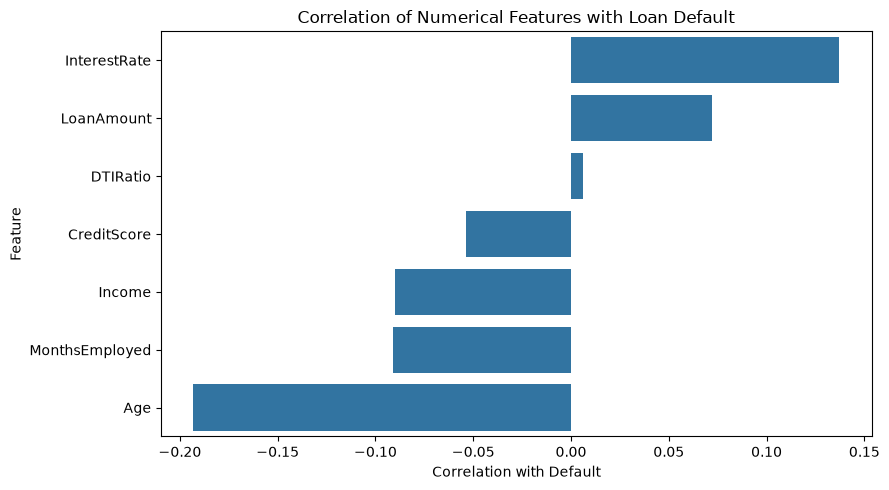

In [24]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=correlation_df,
    x="Correlation with Default",
    y="Feature"
)

plt.title("Correlation of Numerical Features with Loan Default")
plt.tight_layout()

plt.savefig(
    GRAPHS_DIR / "feature_correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Step 5 — Prepare features for machine learning

In [25]:
print("Duplicate rows:", df.count() - df.dropDuplicates().count())
print("Unique Loan IDs:", df.select("LoanID").distinct().count())

Duplicate rows: 0
Unique Loan IDs: 5000


## Preliminary experiments (superseded)

The cells from here to the end of the model evaluation use a simple 80/20 random split with no validation set, no class weights and the default 0.5 threshold. They are retained to show why the final workflow was needed. **Do not cite these metrics as final results.**

In [26]:
train_df, test_df = df.randomSplit([0.8, 0.2], seed=42)

print("Training records:", train_df.count())
print("Testing records:", test_df.count())

print("Training target distribution:")
train_df.groupBy("Default").count().show()

print("Testing target distribution:")
test_df.groupBy("Default").count().show()

Training records: 4042
Testing records: 958
Training target distribution:
+-------+-----+
|Default|count|
+-------+-----+
|      0| 3583|
|      1|  459|
+-------+-----+

Testing target distribution:
+-------+-----+
|Default|count|
+-------+-----+
|      0|  831|
|      1|  127|
+-------+-----+



In [27]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    StringIndexer,
    OneHotEncoder,
    VectorAssembler
)

numeric_features = [
    "Age", "Income", "LoanAmount",
    "CreditScore", "MonthsEmployed",
    "NumCreditLines", "InterestRate",
    "LoanTerm", "DTIRatio"
]

categorical_features = [
    "Education", "EmploymentType",
    "MaritalStatus", "HasMortgage",
    "HasDependents", "LoanPurpose",
    "HasCoSigner"
]

indexers = [
    StringIndexer(
        inputCol=c,
        outputCol=c + "_Index",
        handleInvalid="keep"
    )
    for c in categorical_features
]

encoder = OneHotEncoder(
    inputCols=[c + "_Index" for c in categorical_features],
    outputCols=[c + "_Encoded" for c in categorical_features],
    handleInvalid="keep"
)

assembler = VectorAssembler(
    inputCols=numeric_features + [
        c + "_Encoded" for c in categorical_features
    ],
    outputCol="features",
    handleInvalid="keep"
)

feature_pipeline = Pipeline(
    stages=indexers + [encoder, assembler]
)

feature_model = feature_pipeline.fit(train_df)

train_prepared = feature_model.transform(train_df)
test_prepared = feature_model.transform(test_df)

train_prepared.select("features", "Default").show(5, truncate=False)

+-------------------------------------------------------------------------------------------------------------------------------+-------+
|features                                                                                                                       |Default|
+-------------------------------------------------------------------------------------------------------------------------------+-------+
|(38,[0,1,2,3,4,5,6,7,8,9,17,19,23,27,33,36],[21.0,20463.0,46492.0,568.0,64.0,3.0,7.37,48.0,0.58,1.0,1.0,1.0,1.0,1.0,1.0,1.0])  |0      |
|(38,[0,1,2,3,4,5,6,7,8,9,17,21,23,27,32,35],[34.0,28199.0,103972.0,514.0,6.0,3.0,12.0,60.0,0.23,1.0,1.0,1.0,1.0,1.0,1.0,1.0])  |1      |
|(38,[0,1,2,3,4,5,6,7,8,9,16,19,23,26,32,36],[44.0,24638.0,79385.0,399.0,71.0,2.0,2.76,48.0,0.65,1.0,1.0,1.0,1.0,1.0,1.0,1.0])  |0      |
|(38,[0,1,2,3,4,5,6,7,8,10,17,20,24,27,33,35],[30.0,29979.0,116667.0,783.0,6.0,1.0,5.55,48.0,0.8,1.0,1.0,1.0,1.0,1.0,1.0,1.0])  |0      |
|(38,[0,1,2,3,4,5,6,7,8,10,16,20,2

Step 6 — Train classification models

6.1 Logistic Regression

In [28]:
from pyspark.ml.classification import LogisticRegression

lr = LogisticRegression(
    featuresCol="features",
    labelCol="Default",
    maxIter=100
)

lr_model = lr.fit(train_prepared)

lr_predictions = lr_model.transform(test_prepared)

lr_predictions.select(
    "Default", "prediction", "probability"
).show(10, truncate=False)

+-------+----------+-----------------------------------------+
|Default|prediction|probability                              |
+-------+----------+-----------------------------------------+
|0      |0.0       |[0.8338285697345484,0.16617143026545156] |
|0      |0.0       |[0.9722891109014042,0.02771088909859576] |
|1      |0.0       |[0.7088396195464328,0.2911603804535672]  |
|0      |0.0       |[0.6554279431959622,0.3445720568040378]  |
|0      |0.0       |[0.9338590980678017,0.06614090193219835] |
|0      |0.0       |[0.9672611310283813,0.032738868971618706]|
|0      |0.0       |[0.8041583333584282,0.19584166664157177] |
|0      |0.0       |[0.9534041227156345,0.04659587728436554] |
|0      |0.0       |[0.9456857777148784,0.054314222285121616]|
|0      |0.0       |[0.9062017755999827,0.09379822440001728] |
+-------+----------+-----------------------------------------+
only showing top 10 rows



6.2 Random Forest

In [29]:
from pyspark.ml.classification import RandomForestClassifier

rf = RandomForestClassifier(
    featuresCol="features",
    labelCol="Default",
    numTrees=100,
    maxDepth=8,
    seed=42
)

rf_model = rf.fit(train_prepared)

rf_predictions = rf_model.transform(test_prepared)

rf_predictions.select(
    "Default", "prediction", "probability"
).show(10, truncate=False)

+-------+----------+-----------------------------------------+
|Default|prediction|probability                              |
+-------+----------+-----------------------------------------+
|0      |0.0       |[0.8236678773373795,0.1763321226626206]  |
|0      |0.0       |[0.9534255988845821,0.046574401115417836]|
|1      |0.0       |[0.8723909985781608,0.1276090014218392]  |
|0      |0.0       |[0.8129190583666754,0.1870809416333246]  |
|0      |0.0       |[0.9105072611327332,0.08949273886726682] |
|0      |0.0       |[0.92092111341884,0.07907888658116011]   |
|0      |0.0       |[0.8456632841522836,0.15433671584771627] |
|0      |0.0       |[0.9275812380211345,0.07241876197886554] |
|0      |0.0       |[0.9472868194114191,0.052713180588580814]|
|0      |0.0       |[0.881247150765053,0.118752849234947]    |
+-------+----------+-----------------------------------------+
only showing top 10 rows



6.3 Evaluate both models

In [36]:
import builtins
from pyspark.ml.evaluation import BinaryClassificationEvaluator

def evaluate_model(predictions, model_name):

    tp = predictions.filter(
        (col("Default") == 1) & (col("prediction") == 1)
    ).count()

    tn = predictions.filter(
        (col("Default") == 0) & (col("prediction") == 0)
    ).count()

    fp = predictions.filter(
        (col("Default") == 0) & (col("prediction") == 1)
    ).count()

    fn = predictions.filter(
        (col("Default") == 1) & (col("prediction") == 0)
    ).count()

    precision = tp / (tp + fp) if (tp + fp) else 0
    recall = tp / (tp + fn) if (tp + fn) else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) else 0
    )

    accuracy = (tp + tn) / (tp + tn + fp + fn)

    auc = BinaryClassificationEvaluator(
        labelCol="Default",
        rawPredictionCol="rawPrediction",
        metricName="areaUnderROC"
    ).evaluate(predictions)

    print(f"\n{model_name}")
    print("-" * 35)
    print("Accuracy :", builtins.round(accuracy, 4))
    print("Precision:", builtins.round(precision, 4))
    print("Recall   :", builtins.round(recall, 4))
    print("F1 Score :", builtins.round(f1, 4))
    print("ROC-AUC  :", builtins.round(auc, 4))

    print("\nConfusion Matrix:")
    print(f"TN: {tn} | FP: {fp}")
    print(f"FN: {fn} | TP: {tp}")

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": auc
    }

In [37]:
lr_results = evaluate_model(lr_predictions, "Logistic Regression")
rf_results = evaluate_model(rf_predictions, "Random Forest")

results_df = pd.DataFrame([lr_results, rf_results])
print(results_df)


Logistic Regression
-----------------------------------
Accuracy : 0.8706
Precision: 0.7143
Recall   : 0.0394
F1 Score : 0.0746
ROC-AUC  : 0.7523

Confusion Matrix:
TN: 829 | FP: 2
FN: 122 | TP: 5

Random Forest
-----------------------------------
Accuracy : 0.8674
Precision: 0
Recall   : 0.0
F1 Score : 0
ROC-AUC  : 0.7305

Confusion Matrix:
TN: 831 | FP: 0
FN: 127 | TP: 0
                 Model  Accuracy  Precision   Recall  F1 Score   ROC-AUC
0  Logistic Regression  0.870564   0.714286  0.03937  0.074627  0.752276
1        Random Forest  0.867432   0.000000  0.00000  0.000000  0.730512


> **End of preliminary experiments.** The unweighted models above predicted almost no defaults at the default 0.5 threshold (Logistic Regression recall 0.039, Random Forest recall 0.0 on an 80/20 split), which motivated class weighting and threshold tuning in the final workflow.

## Final leakage-safe workflow

The reproducible continuation is implemented in `scripts/run_workflow.py`. It preserves this EDA, uses stratified 64:16:20 train/validation/test splits, tunes thresholds on validation data only, compares weighted and unweighted models, and evaluates the selected complete pipeline once on the untouched test set.

Run `.venv/bin/python scripts/run_workflow.py` from the project root to regenerate the model, metrics, predictions, and charts.

In [ ]:
import json
from pathlib import Path

metrics_path = PROJECT_ROOT / "outputs" / "tables" / "final_test_metrics.json"
if metrics_path.exists():
    print(json.loads(metrics_path.read_text()))
else:
    print("Run scripts/run_workflow.py first to generate final metrics.")